# UTS — Statistics for Data Science

Notebook ini menggabungkan seluruh requirement UTS menggunakan dataset project **data-set-visualization-statistic-thesis**:

1. Analisis deskriptif.
2. Korelasi Pearson.
3. Welch independent-samples t-test.
4. Mann–Whitney U sebagai uji non-parametrik.

**Batasan data:** execution_time_sec, token_usage, accuracy_score, test_pass_rate, dan error_count adalah data sintetis untuk pembelajaran. Data tersebut bukan hasil eksekusi Codex/AI yang sebenarnya, bukan benchmark produksi, dan tidak boleh digunakan untuk klaim kausal atau generalisasi di luar sampel sintetis ini.

Untuk analisis inferensial, lima observasi berulang pada setiap task dirata-ratakan per ticket_id. Dengan demikian, unit analisisnya adalah task migration, bukan lima baris eksekusi yang dianggap independen.

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

# Notebook dapat dijalankan dari repository root maupun folder analysis.
candidate_roots = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    root for root in candidate_roots
    if (root / "data" / "migration_tasks.csv").exists()
)
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

NUMERIC_METRICS = [
    "execution_time_sec",
    "token_usage",
    "accuracy_score",
    "test_pass_rate",
    "error_count",
]
plt.style.use("seaborn-v0_8-whitegrid")

print(f"Project root: {PROJECT_ROOT}")
print(f"Python: {platform.python_version()}")
for package in ("pandas", "numpy", "scipy", "matplotlib"):
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/alamsyahd/PycharmProjects/data-set-visualization-statistic-thesis
Python: 3.9.6
pandas: 2.3.3
numpy: 2.0.2
scipy: 1.13.1
matplotlib: 3.9.4


## 1. Memuat dan memvalidasi dataset

In [2]:
tasks = pd.read_csv(DATA_DIR / "migration_tasks.csv", dtype=str)
observations = pd.read_csv(
    DATA_DIR / "migration_observations.csv",
    dtype={
        "observation_id": str,
        "ticket_id": str,
        "agent_id": str,
        "execution_time_sec": float,
        "token_usage": int,
        "accuracy_score": float,
        "test_pass_rate": float,
        "error_count": int,
        "status": str,
        "data_status": str,
    },
)

required_task_columns = {
    "ticket_id", "component_area", "migration_task",
    "migration_category", "difficulty",
}
required_observation_columns = {
    "observation_id", "ticket_id", "agent_id",
    *NUMERIC_METRICS, "status", "data_status",
}
assert required_task_columns.issubset(tasks.columns)
assert required_observation_columns.issubset(observations.columns)
assert not tasks.isna().any().any()
assert not observations.isna().any().any()
assert tasks["ticket_id"].is_unique
assert observations["observation_id"].is_unique
assert set(observations["ticket_id"]).issubset(set(tasks["ticket_id"]))
assert (observations["execution_time_sec"] >= 0).all()
assert (observations["token_usage"] >= 0).all()
assert observations["accuracy_score"].between(0, 1).all()
assert observations["test_pass_rate"].between(0, 1).all()
assert (observations["error_count"] >= 0).all()
assert observations["data_status"].eq("synthetic").all()

joined = observations.merge(
    tasks,
    on="ticket_id",
    how="left",
    validate="many_to_one",
)

validation_report = pd.DataFrame({
    "check": [
        "schema", "missing values", "unique IDs", "foreign-key coverage",
        "numeric ranges", "synthetic data label",
    ],
    "result": ["PASS"] * 6,
})
display(validation_report)
print(f"Task catalog: {len(tasks)} tasks")
print(f"Execution observations: {len(observations)} rows")
print(f"Observations per task: {observations.groupby('ticket_id').size().value_counts().to_dict()}")

,check,result
0,schema,PASS
1,missing values,PASS
2,unique IDs,PASS
3,foreign-key coverage,PASS
4,numeric ranges,PASS
5,synthetic data label,PASS


Task catalog: 36 tasks
Execution observations: 180 rows
Observations per task: {5: 36}


## 2. Analisis deskriptif

Analisis deskriptif dilakukan pada seluruh observasi eksekusi. Statistik yang dihitung meliputi mean, median, mode, standar deviasi, variance, minimum, kuartil, dan IQR. Frequency summary digunakan untuk variabel kategorikal.

In [3]:
summary_rows = []
outlier_rows = []
for column in NUMERIC_METRICS:
    series = observations[column]
    q1 = series.quantile(0.25)
    median = series.quantile(0.50)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    mode_values = series.mode().tolist()
    summary_rows.append({
        "variable": column,
        "count": int(series.count()),
        "mean": series.mean(),
        "median": median,
        "mode": "; ".join(map(str, mode_values)),
        "mode_frequency": int(series.value_counts().iloc[0]),
        "std_dev": series.std(ddof=1),
        "variance": series.var(ddof=1),
        "minimum": series.min(),
        "q1": q1,
        "q2": median,
        "q3": q3,
        "maximum": series.max(),
        "iqr": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
    })
    mask = (series < lower_fence) | (series > upper_fence)
    if mask.any():
        detected = observations.loc[mask, ["observation_id", "ticket_id", column]].copy()
        detected = detected.rename(columns={column: "value"})
        detected["variable"] = column
        detected["lower_fence"] = lower_fence
        detected["upper_fence"] = upper_fence
        outlier_rows.append(detected)

descriptive_summary = pd.DataFrame(summary_rows)
outliers = (
    pd.concat(outlier_rows, ignore_index=True)
    if outlier_rows else
    pd.DataFrame(columns=["observation_id", "ticket_id", "value", "variable", "lower_fence", "upper_fence"])
)
descriptive_summary.to_csv(OUTPUT_DIR / "uts_descriptive_summary.csv", index=False)
outliers.to_csv(OUTPUT_DIR / "uts_outliers.csv", index=False)
display(descriptive_summary.round(4))
print(f"Potential outlier records detected: {len(outliers)}")

categorical_columns = [
    "component_area", "migration_category", "difficulty", "agent_id", "status",
]
frequency_tables = []
for column in categorical_columns:
    counts = joined[column].value_counts(dropna=False).rename_axis(column).reset_index(name="count")
    counts["percentage"] = counts["count"] / len(joined) * 100
    frequency_tables.append(counts.assign(variable=column))
    display(Markdown(f"### Frequency: {column}"))
    display(counts)
categorical_frequencies = pd.concat(frequency_tables, ignore_index=True)
categorical_frequencies.to_csv(OUTPUT_DIR / "uts_categorical_frequencies.csv", index=False)

,variable,count,mean,median,mode,mode_frequency,std_dev,variance,minimum,q1,q2,q3,maximum,iqr,lower_fence,upper_fence
0,execution_time_sec,180,88.0261,81.500,63.1,3,39.3230,1546.2974,34.400,63.075,81.500,104.3500,317.700,41.2750,1.1625,166.2625
1,token_usage,180,2316.0167,2213.500,2674,3,465.2356,216444.1617,1627.000,2010.000,2213.500,2574.2500,5122.000,564.2500,1163.6250,3420.6250
2,accuracy_score,180,0.9070,0.911,0.887,6,0.0510,0.0026,0.683,0.879,0.911,0.9418,0.995,0.0627,0.7849,1.0359
3,test_pass_rate,180,0.9398,0.941,1.0,19,0.0461,0.0021,0.688,0.916,0.941,0.9702,1.000,0.0542,0.8346,1.0516
4,error_count,180,0.7667,1.000,0,79,0.9099,0.8279,0.000,0.000,1.000,1.0000,6.000,1.0000,-1.5000,2.5000


Potential outlier records detected: 18


### Frequency: component_area

,component_area,count,percentage
0,Balance,40,22.222222
1,Quick Action,40,22.222222
2,App Bar,30,16.666667
3,Transactions,25,13.888889
4,UI States,25,13.888889
5,Promo,20,11.111111


### Frequency: migration_category

...

,difficulty,count,percentage
0,Medium,95,52.777778
1,Hard,50,27.777778
2,Easy,35,19.444444


### Frequency: agent_id

,agent_id,count,percentage
0,synthetic-agent-A,60,33.333333
1,synthetic-agent-B,60,33.333333
2,synthetic-agent-C,60,33.333333


### Frequency: status

,status,count,percentage
0,Passed,114,63.333333
1,Passed with fixes,63,35.000000
2,Failed,3,1.666667


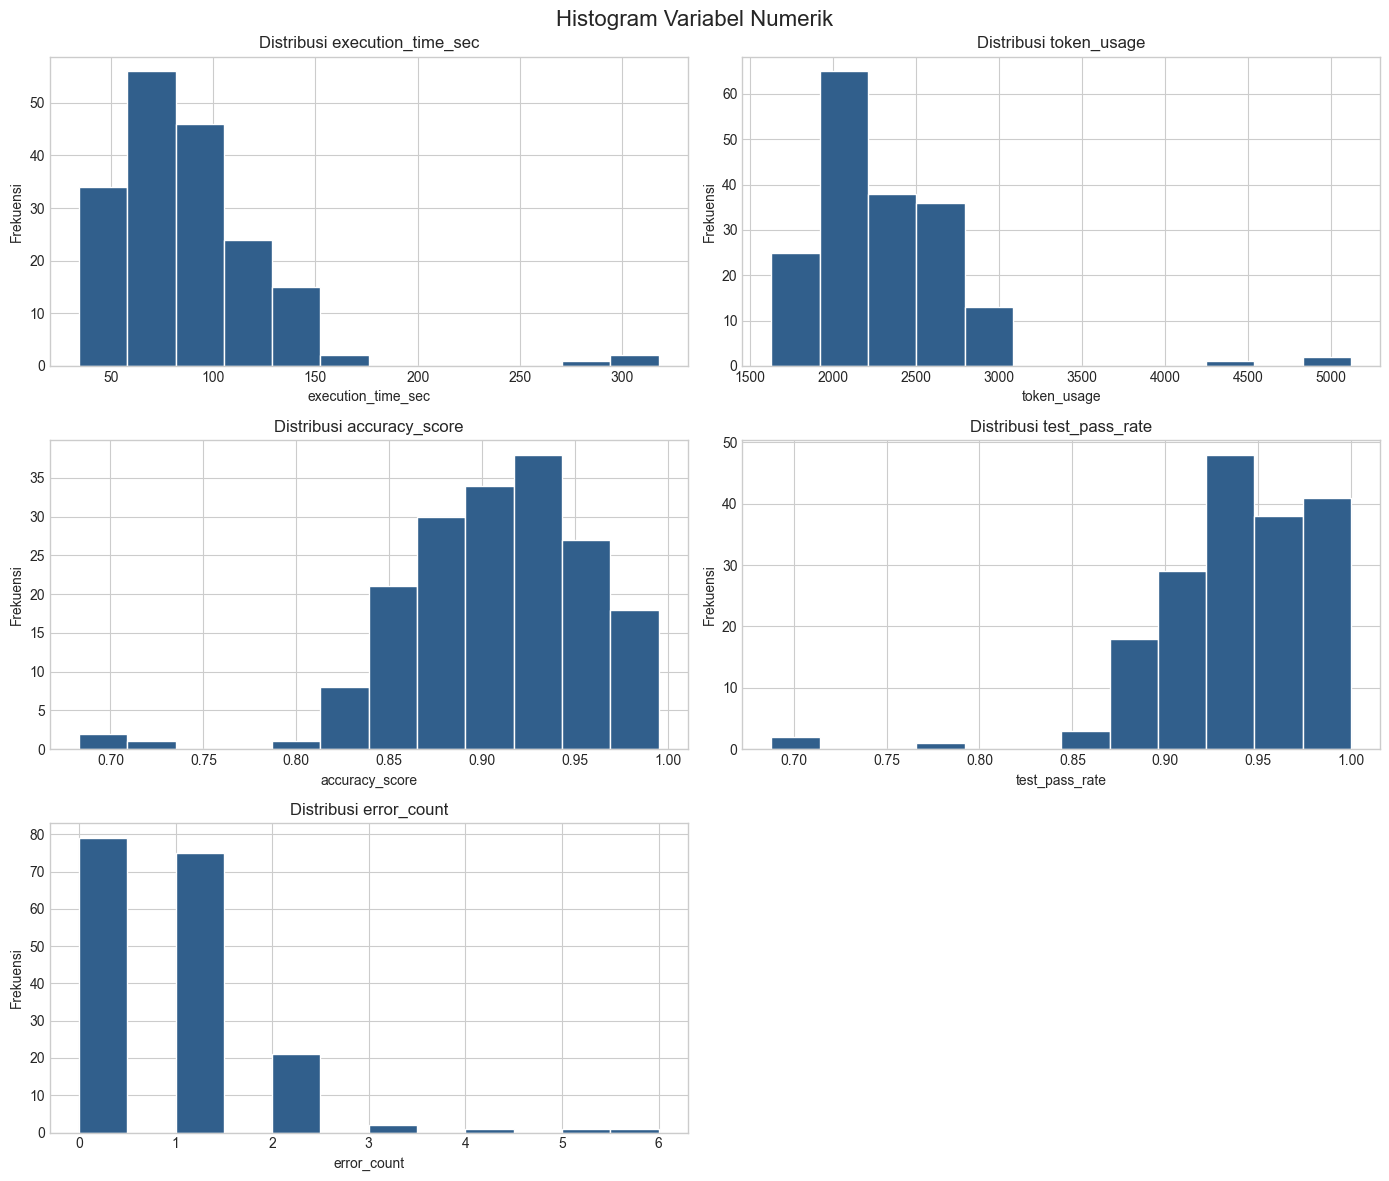

/var/folders/ny/n29nst_x6318_bsnhml1g5tw0000gq/T/ipykernel_84370/3354916126.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axis.boxplot([observations[column] for column in NUMERIC_METRICS], labels=NUMERIC_METRICS)


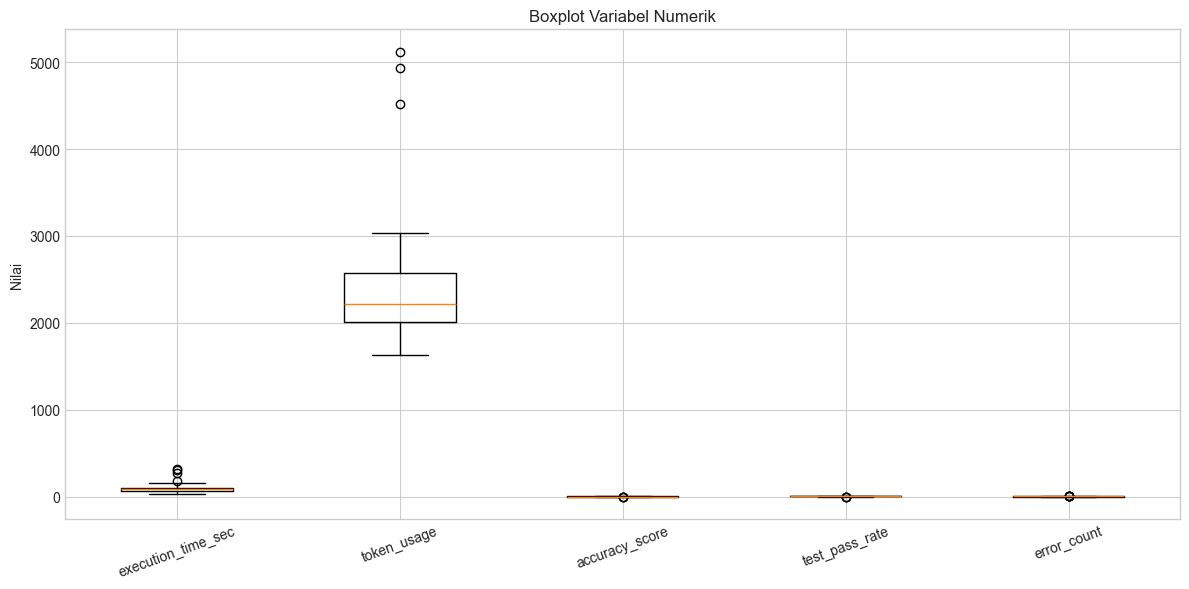

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for axis, column in zip(axes.flat, NUMERIC_METRICS):
    axis.hist(observations[column], bins=12, color="#315f8c", edgecolor="white")
    axis.set_title(f"Distribusi {column}")
    axis.set_xlabel(column)
    axis.set_ylabel("Frekuensi")
axes.flat[-1].axis("off")
fig.suptitle("Histogram Variabel Numerik", fontsize=16)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "uts_numeric_histograms.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axis = plt.subplots(figsize=(12, 6))
axis.boxplot([observations[column] for column in NUMERIC_METRICS], labels=NUMERIC_METRICS)
axis.set_title("Boxplot Variabel Numerik")
axis.set_ylabel("Nilai")
axis.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "uts_numeric_boxplots.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Unit analisis untuk pengujian inferensial

Setiap task memiliki lima execution records. Untuk mencegah pseudo-replication, nilai numerik dirata-ratakan per task. Metadata task kemudian digunakan untuk membentuk kelompok difficulty.

In [5]:
task_level = (
    observations.groupby("ticket_id", as_index=False)[NUMERIC_METRICS]
    .mean()
    .merge(tasks, on="ticket_id", how="left", validate="one_to_one")
)
display(task_level.groupby("difficulty").agg(
    task_count=("ticket_id", "count"),
    mean_execution_time_sec=("execution_time_sec", "mean"),
    median_execution_time_sec=("execution_time_sec", "median"),
).round(4))
print(f"Task-level observations: {len(task_level)}")

,task_count,mean_execution_time_sec,median_execution_time_sec
difficulty,,,
Easy,7,52.5057,49.98
Hard,10,130.7520,125.53
Medium,19,78.6253,78.54


Task-level observations: 36


## 4. Korelasi Pearson

Korelasi Pearson dipilih untuk menguji hubungan linear antara rata-rata waktu eksekusi dan rata-rata token usage pada tingkat task. Hasil hanya menunjukkan asosiasi dalam sampel sintetis ini dan bukan hubungan sebab-akibat.

,test,variables,n,coefficient_r,p_value,decision_alpha_0_05
0,Pearson correlation,mean execution_time_sec vs mean token_usage,36,0.960757,0.0,Significant


Interpretasi: r=0.961 menunjukkan asosiasi linear positif yang kuat; p=1.64e-20.


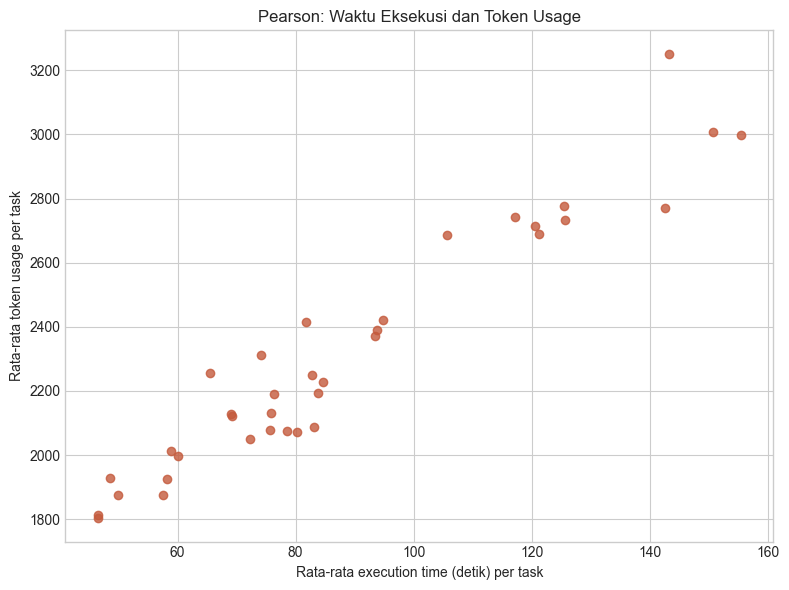

In [6]:
pearson = stats.pearsonr(task_level["execution_time_sec"], task_level["token_usage"])
correlation_result = {
    "test": "Pearson correlation",
    "variables": "mean execution_time_sec vs mean token_usage",
    "n": len(task_level),
    "coefficient_r": pearson.statistic,
    "p_value": pearson.pvalue,
    "decision_alpha_0_05": "Significant" if pearson.pvalue < 0.05 else "Not significant",
}
display(pd.DataFrame([correlation_result]).round(6))
print(
    f"Interpretasi: r={pearson.statistic:.3f} menunjukkan asosiasi linear positif "
    f"yang kuat; p={pearson.pvalue:.3g}."
)

fig, axis = plt.subplots(figsize=(8, 6))
axis.scatter(task_level["execution_time_sec"], task_level["token_usage"], color="#c45a3c", alpha=0.8)
axis.set_title("Pearson: Waktu Eksekusi dan Token Usage")
axis.set_xlabel("Rata-rata execution time (detik) per task")
axis.set_ylabel("Rata-rata token usage per task")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "uts_pearson_time_vs_tokens.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Welch independent-samples t-test

Uji Welch digunakan untuk membandingkan rata-rata waktu eksekusi task Hard dan Easy tanpa mengasumsikan variance kedua kelompok sama. Hipotesis nol: rata-rata kedua kelompok sama.

In [7]:
hard = task_level.loc[task_level["difficulty"] == "Hard", "execution_time_sec"].to_numpy()
easy = task_level.loc[task_level["difficulty"] == "Easy", "execution_time_sec"].to_numpy()
welch = stats.ttest_ind(hard, easy, equal_var=False)
hard_mean = hard.mean()
easy_mean = easy.mean()
mean_difference = hard_mean - easy_mean
hard_var = hard.var(ddof=1)
easy_var = easy.var(ddof=1)
standard_error = np.sqrt(hard_var / len(hard) + easy_var / len(easy))
welch_df = (hard_var / len(hard) + easy_var / len(easy)) ** 2 / (
    (hard_var / len(hard)) ** 2 / (len(hard) - 1)
    + (easy_var / len(easy)) ** 2 / (len(easy) - 1)
)
critical_value = stats.t.ppf(0.975, welch_df)
ci_low = mean_difference - critical_value * standard_error
ci_high = mean_difference + critical_value * standard_error
welch_result = {
    "test": "Welch independent-samples t-test",
    "group_a": "Hard",
    "group_b": "Easy",
    "n_hard": len(hard),
    "n_easy": len(easy),
    "mean_hard": hard_mean,
    "mean_easy": easy_mean,
    "difference_hard_minus_easy": mean_difference,
    "t_statistic": welch.statistic,
    "degrees_of_freedom": welch_df,
    "p_value": welch.pvalue,
    "95pct_ci_low": ci_low,
    "95pct_ci_high": ci_high,
    "decision_alpha_0_05": "Reject H0" if welch.pvalue < 0.05 else "Fail to reject H0",
}
display(pd.DataFrame([welch_result]).round(6))
print(
    f"Interpretasi: rata-rata Hard ({hard_mean:.2f} detik) lebih tinggi daripada "
    f"Easy ({easy_mean:.2f} detik); p={welch.pvalue:.3g}."
)

,test,group_a,group_b,n_hard,n_easy,mean_hard,mean_easy,difference_hard_minus_easy,t_statistic,degrees_of_freedom,p_value,95pct_ci_low,95pct_ci_high,decision_alpha_0_05
0,Welch independent-samples t-test,Hard,Easy,10,7,130.752,52.505714,78.246286,14.001607,12.089096,0.0,66.0802,90.412372,Reject H0


Interpretasi: rata-rata Hard (130.75 detik) lebih tinggi daripada Easy (52.51 detik); p=7.8e-09.


## 6. Uji non-parametrik Mann–Whitney U

Mann–Whitney U digunakan sebagai uji non-parametrik untuk membandingkan distribusi waktu eksekusi task Hard dan Easy. Hipotesis nol: distribusi kedua kelompok sama.

In [8]:
mann_whitney = stats.mannwhitneyu(hard, easy, alternative="two-sided", method="auto")
mann_result = {
    "test": "Mann-Whitney U",
    "group_a": "Hard",
    "group_b": "Easy",
    "n_hard": len(hard),
    "n_easy": len(easy),
    "median_hard": np.median(hard),
    "median_easy": np.median(easy),
    "U_statistic": mann_whitney.statistic,
    "p_value": mann_whitney.pvalue,
    "decision_alpha_0_05": "Reject H0" if mann_whitney.pvalue < 0.05 else "Fail to reject H0",
}
display(pd.DataFrame([mann_result]).round(6))
print(
    f"Interpretasi: distribusi waktu eksekusi Hard dan Easy berbeda secara signifikan; "
    f"p={mann_whitney.pvalue:.3g}."
)

inferential_summary = pd.DataFrame([
    {"analysis": "Pearson correlation", "statistic": pearson.statistic, "p_value": pearson.pvalue, "decision": correlation_result["decision_alpha_0_05"]},
    {"analysis": "Welch t-test", "statistic": welch.statistic, "p_value": welch.pvalue, "decision": welch_result["decision_alpha_0_05"]},
    {"analysis": "Mann-Whitney U", "statistic": mann_whitney.statistic, "p_value": mann_whitney.pvalue, "decision": mann_result["decision_alpha_0_05"]},
])
inferential_summary.to_csv(OUTPUT_DIR / "uts_inferential_summary.csv", index=False)

,test,group_a,group_b,n_hard,n_easy,median_hard,median_easy,U_statistic,p_value,decision_alpha_0_05
0,Mann-Whitney U,Hard,Easy,10,7,125.53,49.98,70.0,0.000103,Reject H0


Interpretasi: distribusi waktu eksekusi Hard dan Easy berbeda secara signifikan; p=0.000103.


## 7. Kesimpulan UTS

- Dataset valid untuk analisis deskriptif karena memiliki variabel numerik dan kategorikal yang jelas, data tidak kosong, ID unik, dan hubungan task–observation yang valid.
- Pada tingkat task, terdapat asosiasi linear positif yang kuat antara rata-rata waktu eksekusi dan rata-rata token usage.
- Welch t-test menunjukkan rata-rata waktu eksekusi task Hard lebih tinggi daripada Easy pada sampel sintetis ini.
- Mann–Whitney U juga menunjukkan perbedaan distribusi waktu eksekusi Hard dan Easy.
- Semua kesimpulan bersifat deskriptif untuk dataset sintetis ini. Hasil tidak membuktikan sebab-akibat, tidak mewakili performa AI/production, dan tidak boleh digeneralisasikan ke populasi lain.